# Übung X - Aufgabe 1 - Convolutional Neural Networks (CNNs)

In diesem Notebook betrachten wir, wie **1D- und 2D-Convolutional Neural Networks** funktionieren.  
Dabei untersuchen wir den Einfluss verschiedener Parameter wie **Kernelgröße**, **Stride**, **Padding**, **Dilation** und **Anzahl der Kanäle** auf das Verhalten von CNNs.

Ziel ist es, ein intuitives Verständnis für die Funktionsweise und die Auswirkungen dieser Parameter zu entwickeln – sowohl bei eindimensionalen Sequenzen als auch bei zweidimensionalen Bildern.


### Nötige Imports durchführen

In [11]:
from IPython.display import SVG, display
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from torchvision import datasets, transforms

## Einführung in Faltungen 


###  Was ist eine Faltung?

Eine Faltung ist eine gewichtete Summe von Eingabewerten, bei der ein "Kernel" (Filter) über ein Signal oder Bild geschoben wird.
<img src="https://media0.giphy.com/media/v1.Y2lkPTc5MGI3NjExaHI4c2pnbmFsYzYzZ2l6enR1cms2dWM4amhmd2F3NmR1N2JqemV4NiZlcD12MV9pbnRlcm5hbF9naWZfYnlfaWQmY3Q9Zw/i4NjAwytgIRDW/giphy.gif" alt="Giphy Beispiel" />


## Visualisierung: 1D Convolution mit unterschiedlichem Stride

Das folgende Bild zeigt, wie ein 1D-CNN-Filter der Länge 3 über eine Eingabesequenz der Länge 9 gleitet – bei verschiedenen Stride-Werten:

- **Oben (Stride = 1)**:  
  Der Filter bewegt sich **schrittweise** über jedes Element → es entstehen **7 Ausgabewerte** `c[0]` bis `c[6]`.

- **Mitte (Stride = 2)**:  
  Der Filter springt **alle 2 Schritte** → es entstehen **4 Ausgabewerte** `c[0]` bis `c[3]`.

- **Unten (Stride = 3)**:  
  Der Filter springt **alle 3 Schritte** → es entstehen **3 Ausgabewerte** `c[0]` bis `c[2]`.

Die Eingabesequenz bleibt in allen Fällen gleich (`x[0]` bis `x[8]`), aber die Ausgabelänge variiert durch den Stride.


<img src="./figures/1d_cnn_stride.svg" alt="Kleines Bild" width="600"/>



Schauen wir uns mal an, wie sowas in Code aussehen würde




In [12]:
# Eingabe: Länge 9
x = torch.tensor([[[1., 2., 3., 4., 5., 6., 7., 8., 9.]]])  # Shape: [1, 1, 9]

conv = ### Hier 2D-Conv Layer definieren

# Einfacher Summen-Filter
conv.weight.data = torch.tensor([[[1., 1., 1.]]])  


SyntaxError: invalid syntax (3920577222.py, line 4)

Beispiel 1: Stride = 1

Bei Stride 1 wird der Filter an jeder möglichen Position angewendet.  
Den Stride-Wert können Sie mit ```conv.stride``` anpassen

In [ ]:
### Hier Stride ändern vom conv Layer


output_s1 = conv(x)

print("Stride = 1, Output Shape:", output_s1.shape)
print(output_s1)


Beispiel 2: Stride = 2

Bei Stride 2 wird der Filter alle zwei Schritte über die Eingabe geschoben.


In [ ]:
### Hier Stride ändern vom conv Layer


output_s2 = conv(x)

print("Stride = 2, Output Shape:", output_s2.shape)
print(output_s2)


Beispiel 3: Stride = 3

Bei Stride 3 wird der Filter nur jede dritte Position entlang der Eingabesequenz angewendet.  



In [ ]:
### Hier Stride ändern vom conv Layer


output_s3 = conv(x)

print("Stride = 3, Output Shape:", output_s3.shape)
print(output_s3)

### Warum `in_channels=1` und `out_channels=1`?

In vorherigen Beispiel verarbeiten wir ein eindimensionales Signal mit nur **einem Kanal** – deshalb `in_channels=1`.  
Da wir nur **einen einfachen Filter** (Summenfilter) anwenden, genügt auch `out_channels=1`, um eine einzelne Ausgabe zu erzeugen.


Hier schauen wir uns an, wie man mehrere Eingangskanäle und Ausgabekanäle verwendet.

Ein 1D-Conv-Layer verarbeitet hier 2 Eingangskanäle und berechnet 3 Ausgabekanäle mit jeweils eigenen Filtern – das erlaubt komplexere Merkmalskombinationen.


In [ ]:
# Eingabe mit 2 Kanälen, Länge 9
x = torch.tensor([[
    [1., 2., 3., 4., 5., 6., 7., 8., 9.],        # Kanal 1
    [9., 8., 7., 6., 5., 4., 3., 2., 1.]         # Kanal 2
]], dtype=torch.float32)  # Shape: [1, 2, 9]

conv = ### Hier Conv1d Layer mit 2 Input-Channels, 3 Output-Channels, Kernelgröße 3 definieren


conv.weight.data = ### Hier 3 Output Kanäle definierren

# Anwenden
output = conv(x)

print("Output shape:", output.shape)  
print(output)


## Pooling in 1D CNNs

**Pooling** ist ein Zwischenschritt in Convolutional Neural Networks, der dazu dient, die **Größe der Daten zu reduzieren**, während die **wichtigsten Informationen erhalten bleiben**.

Man kann sich Pooling als eine Art „Zusammenfassung“ vorstellen:
- Statt alle Ausgabewerte des CNN-Filters zu behalten, betrachtet man kleine Abschnitte ("Fenster") und fasst sie **durch eine einfache Operation** zusammen.
- Dadurch wird die **Dimension reduziert** und das Modell **robuster gegenüber kleinen Verschiebungen** in der Eingabe.

Typische Pooling-Methoden:
- **Max Pooling**: wählt den **größten Wert** im Fenster.
- **Average Pooling**: berechnet den **Durchschnitt** im Fenster.

---

Das folgende Bild zeigt, wie **Pooling** auf die Ausgabe eines 1D-CNN angewendet wird:

- **Average Pooling (oben)**:
  - Eingabe: `[1, 5, 3, 1, 1, 1]`
  - Kernelsize: 2, Stride: 2

- **Max Pooling (unten)**:
  - Gleiche Eingabe: `[1, 5, 3, 1, 1, 1]`
  - Kernelsize: 2, Stride: 2

<img src="./figures/1d_cnn_pooling.svg" alt="Kleines Bild" width="600"/>


Definieren Sie hier wie oben in der Zeichnung einen Input Tensor der Länge 6.

Beachten Sie, wie man die Parameter von dem AvgPool1d Layer setzen muss, um die Zechnung korrekt nachzubilden.

In [ ]:
x_pool = ### Hier Input 1D Tensor definieren

# Average Pooling
avg_pool = ### Hier AvgPool1d Layer definieren

avg_output = avg_pool(x_pool)

# Max Pooling 
max_pool = ### Hier MaxPool1d Layer definieren
max_output = max_pool(x_pool)

print("Average Pooling Output:", avg_output)
print("Max Pooling Output:", max_output)

## Zero Padding in 1D CNNs

**Zero Padding** bedeutet, dass man vor der Faltung zusätzliche Nullen an den Rändern der Eingabe hinzufügt. Dadurch kann man:

- die **Länge der Ausgabe gezielt steuern** (z. B. gleich lang wie Eingabe),
- **Randinformationen** besser berücksichtigen,
- und die **Positionssymmetrie** erhalten.

---

### Beispiel (wie im Bild dargestellt)

- **Eingabe (ohne Padding)**: `x[0] ... x[8]` → Länge 9  
- **Nach Padding** (rechts zwei Nullen): `x[0] ... x[8], 0, 0` → Länge 11  
- **Filtergröße**: 3  
- **Stride**: 1  
- **Output-Länge**: 11 - 3 + 1 = 9 → also `c[0] ... c[8]`

Das Padding sorgt hier dafür, dass der Filter **auch ganz am Anfang und ganz am Ende** sinnvoll angewendet werden kann.

<img src="./figures/1d_cnn_zero_padding.svg" alt="Kleines Bild" width="600"/>


In [ ]:
# Eingabesequenz x[0] bis x[8]
x = torch.tensor([[[1., 2., 3., 4., 5., 6., 7., 8., 9.]]])  # Shape: [1, 1, 9]

# Convolution mit Padding = 2
conv = ### Hier Conv1d Layer definieren
conv.weight.data = torch.tensor([[[1., 1., 1.]]]) # Summen Kernel 

output = conv(x)

print("Output Shape:", output.shape)
print("Output:", output)


## Dilation in 1D Convolutional Neural Networks

**Dilation** bedeutet, dass man bei der Faltung **Abstände zwischen die Filterelemente** einfügt. Dadurch wird das **Rezeptionsfeld (also der abgedeckte Eingabebereich)** größer, **ohne** dass der Filter selbst mehr Parameter bekommt.

Das ist besonders nützlich bei:
- Zeitreihen (um lange Abhängigkeiten zu erfassen)
- Sprache oder Audio
- Aufgaben wie z. B. Segmentierung, wo der Kontext wichtig ist


Rechte Seite (```Dilaton = 2```) vergrößert den effektiven Sichtbereich eines Filters, indem es Lücken zwischen den betrachteten Pixeln einführt. 

<img src="./figures/dilation.jpg" alt="Kleines Bild" width="600"/>

Definieren Sie zwei Conv1d-Layer mit einem Filter (einen einfachen Summen Kernel) der ```Kernelgröße``` 3, ```Stride``` 3 und ```Dilation``` 1 bzw. ```Dilation``` 2. Verwenden Sie denselben Filter für beide Layer und analysieren Sie den Einfluss der Dilation auf das Ergebnis der Faltung.


In [ ]:
# Eingabe: 1D-Sequenz
x = torch.tensor([[[1., 2., 3., 4., 5., 6., 7., 8., 9.]]])  # Shape: [1, 1, 9]

# Filter mit Kernelgröße 3, Stride 3, Dilation 1
conv_d1 = ### Hier Conv1d Layer definieren
conv_d1.weight.data = ### Hier Kernel (Filter) definieren

# Filter mit Dilation 2
conv_d2 = ### Hier Conv1d Layer definieren
conv_d2.weight.data =  ### Gleicher Kernel

# Anwendung
out_d1 = conv_d1(x)
out_d2 = conv_d2(x)

print("Dilation = 1 Output:", out_d1)
print("Dilation = 2 Output:", out_d2)


# 2D Blurring und Kantenerkennung
Wir verwenden den MNIST-Datensatz, der handgeschriebene Ziffern von 0 bis 9 in Graustufenbildern enthält.
Dabei betrachten wir nun *zweidimensionale* Bilddaten, um Filteroperationen wie Weichzeichnen (Blurring) und Kantenerkennung in 2D anzuwenden.

In [ ]:
# Bild aus MNIST laden
mnist = datasets.MNIST(root='./data', train=False, download=True, transform=transforms.ToTensor())
img, label = mnist[0]

# Bild anzeigen
plt.imshow(img.squeeze(), cmap='gray')
plt.title(f"Originaler Label: {label}")
plt.axis('off')
plt.show()

### FixedFilter

Ein fester 3×3-Faltungsfilter (z. B. Edge Detection oder Blur), der mit `nn.Conv2d` ohne Lernbarkeit implementiert ist – ideal für klassische Bildverarbeitung.


In [ ]:
class FixedFilter(nn.Module):
    def __init__(self, kernel):
        super().__init__()
        # Filter mit festen Werten, nicht lernbar
        self.conv = nn.Conv2d(1, 1, kernel_size=3, padding=1, bias=False)
        self.conv.weight.data = kernel
        self.conv.weight.requires_grad = False

    def forward(self, x):
        return self.conv(x)


## Edge Detection und Blurring Tensoren definieren

In der Vorlesung haben wir gesehen, wie mögliche Kernel für Kantenerkennung aussehen könnten. 
Wie ein Kernel für Blurring aussehen könnten, sehen Sie [hier](https://en.wikipedia.org/wiki/Kernel_(image_processing))

<img src="./figures/cnn.png" alt="Kleines Bild" width="600"/>

### Feste Filter für Bildverarbeitung

Hier sollen Sie drei 3×3-Filter definiert:
- **Blur-Filter** (Mittelwert): glättet das Bild, indem es lokale Pixelmittelwerte berechnet.
- **Horizontaler Kantenfilter**: hebt horizontale Kanten hervor.
- **Vertikaler Kantenfilter**: hebt vertikale Kanten hervor.

Diese Filter werden mit `FixedFilter` als nicht-trainierbare `Conv2d`-Layer in PyTorch implementiert.


In [ ]:
# Weichzeichner (Blur) 
blur_kernel = ### Hier Bluring Kernel definieren

# Kantendetektor (horizontal)
edge_hor = ### Hier horizontalen Edge Detector Kernel defineiren

# Kantendetektor (vertikal)
edge_ver = ### Hier vertikalen Edge Detector Kernel defineiren

blur = FixedFilter(blur_kernel)
edge_x = FixedFilter(edge_hor)
edge_y = FixedFilter(edge_ver)


### Anwendung fester Filter auf ein Bild

Ein einzelnes Graustufenbild wird mit drei festen Filtern verarbeitet:
- **Blur**: Glättung des Bildes.
- **Kantenkombination**: Berechnung der Kantenstärke durch die euklidische Kombination beider Richtungen.

Die euklidische Distanz kombiniert die horizontalen und vertikalen Gradienten, um die Gesamtstärke der Kante zu bestimmen. Dies liefert eine präzisere Kantenmessung, da beide Richtungen berücksichtigt werden. Alternativ könnte auch der größere der beiden Gradienten verwendet werden.










In [ ]:
with torch.no_grad():
    blurred = blur(img)
    edge_x_img = edge_x(img)
    edge_y_img = edge_y(img)
    edge_combined = torch.sqrt(edge_x_img**2 + edge_y_img**2)  

# Visualisieren
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
axs[0].imshow(img.squeeze(), cmap='gray')
axs[0].set_title("Original")
axs[1].imshow(blurred.squeeze(), cmap='gray')
axs[1].set_title("Blurred")
axs[2].imshow(edge_combined.squeeze(), cmap='gray')
axs[2].set_title("Kantenerkennung")
plt.show()


# 2D-Blur und Kantenerkennung mit RGB-Bildern
In diesem Abschnitt befassen wir uns mit der Verarbeitung von zweidimensionalen RGB-Bildern. Dabei wenden wir Filter an, um Effekte wie Weichzeichnen (Blurring) und Kantenerkennung zu erzielen.

<img src="./figures/kernel.png" alt="Kleines Bild" width="600"/>

## Laden und Vorbereiten des Datensatzes
Wir arbeiten mit dem CIFAR-100-Datensatz und bereiten ihn mit einer Normalisierung für die weitere Verarbeitung vor.


In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5071, 0.4867, 0.4408), (0.2675, 0.2565, 0.2761))
])

trainset = torchvision.datasets.CIFAR100(root='./data', train=True,
                                        download=True, transform=transform)

trainloader = torch.utils.data.DataLoader(trainset, batch_size=4,
                                          shuffle=True, num_workers=2)

# Funktion zum Darstellen der Bilder
def imshow(img):
    img = img / 2 + 0.5  # Denormalisierung
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis('off')


# Beispielbild laden
dataiter = iter(trainloader)
images, labels = next(dataiter)

# Zufällige Bilder anzeigen
imshow(torchvision.utils.make_grid(images))

## Blurring
Nun werden wir ein einfaches Blur anwenden, um das Bild weicher zu machen und Details zu entfernen. Ein Standard-Filter für diese Technik ist der [Box-Filter](https://en.wikipedia.org/wiki/Kernel_(image_processing)).

Blur: Ein Weichzeichnungsfilter (Box-Filter) wird auf das Bild angewendet. Der Filter berechnet den Durchschnitt der Pixel in einem 3x3-Fenster und ersetzt das zentrale Pixel durch den Durchschnittswert. Dies führt zu einer Reduzierung der Detailgenauigkeit und einer Glättung der Kanten.



In [ ]:
class BoxBlur(nn.Module):
    def __init__(self):
        super().__init__()
        self.kernel = ### Hier Box Blur Kernel definieren
    
    def forward(self, x):
        kernel = self.kernel.to(x.device).repeat(3, 1, 1, 1) # wiederholt den Kernel über die 3 Kanäle (für RGB), um sicherzustellen, dass jeder Farbkanal den gleichen Filter erhält.
        return torch.nn.functional.conv2d(x, kernel, groups=3) # groups=3 sorgt dafür, dass der Kernel auf die 3 Kanäle (RGB) des Bildes separat angewendet wird, ohne sie zu vermischen.

# Anwendung
blur = BoxBlur()

# Box Blur anwenden
blurred_images = blur(images)

# Ergebnisse vergleichen
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
imshow(torchvision.utils.make_grid(images))
plt.title("Originalbilder")

plt.subplot(1,2,2)
imshow(torchvision.utils.make_grid(blurred_images))
plt.title("Geblurte Bilder (Box Blur)")
plt.show()


## Edge Detection (Kantenerkennung)
Zur Erkennung von Kanten wenden wir einfache 3×3-Kantenfilter an – getrennt für horizontale und vertikale Richtungen. Diese Filter berechnen Differenzen benachbarter Pixel und heben dadurch Bildbereiche mit starkem Helligkeitswechsel hervor (Kanten). Die kombinierte Gradientenmagnitude zeigt die Kantenintensität.



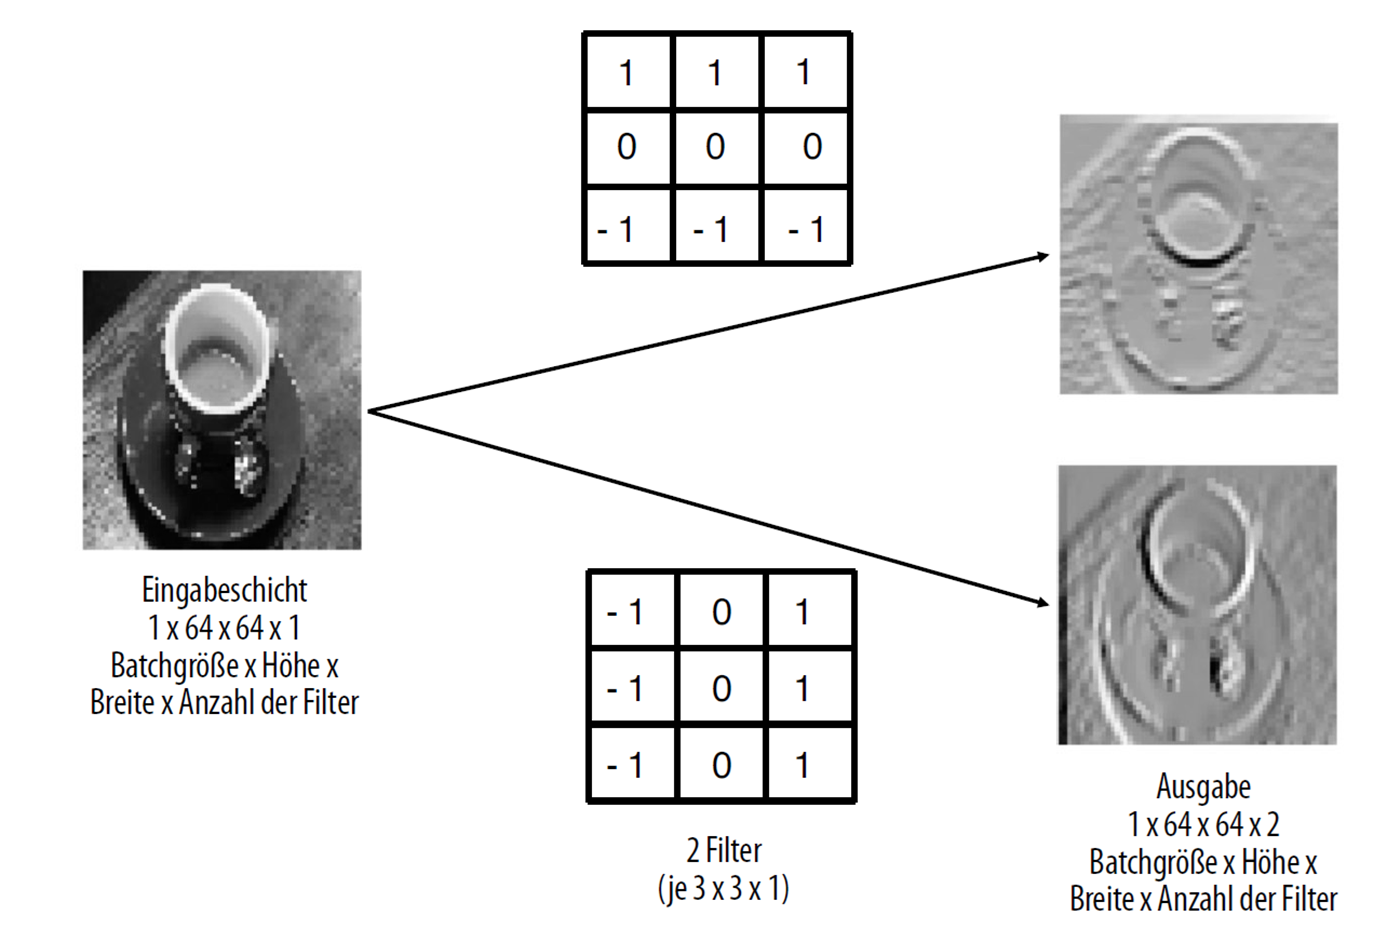
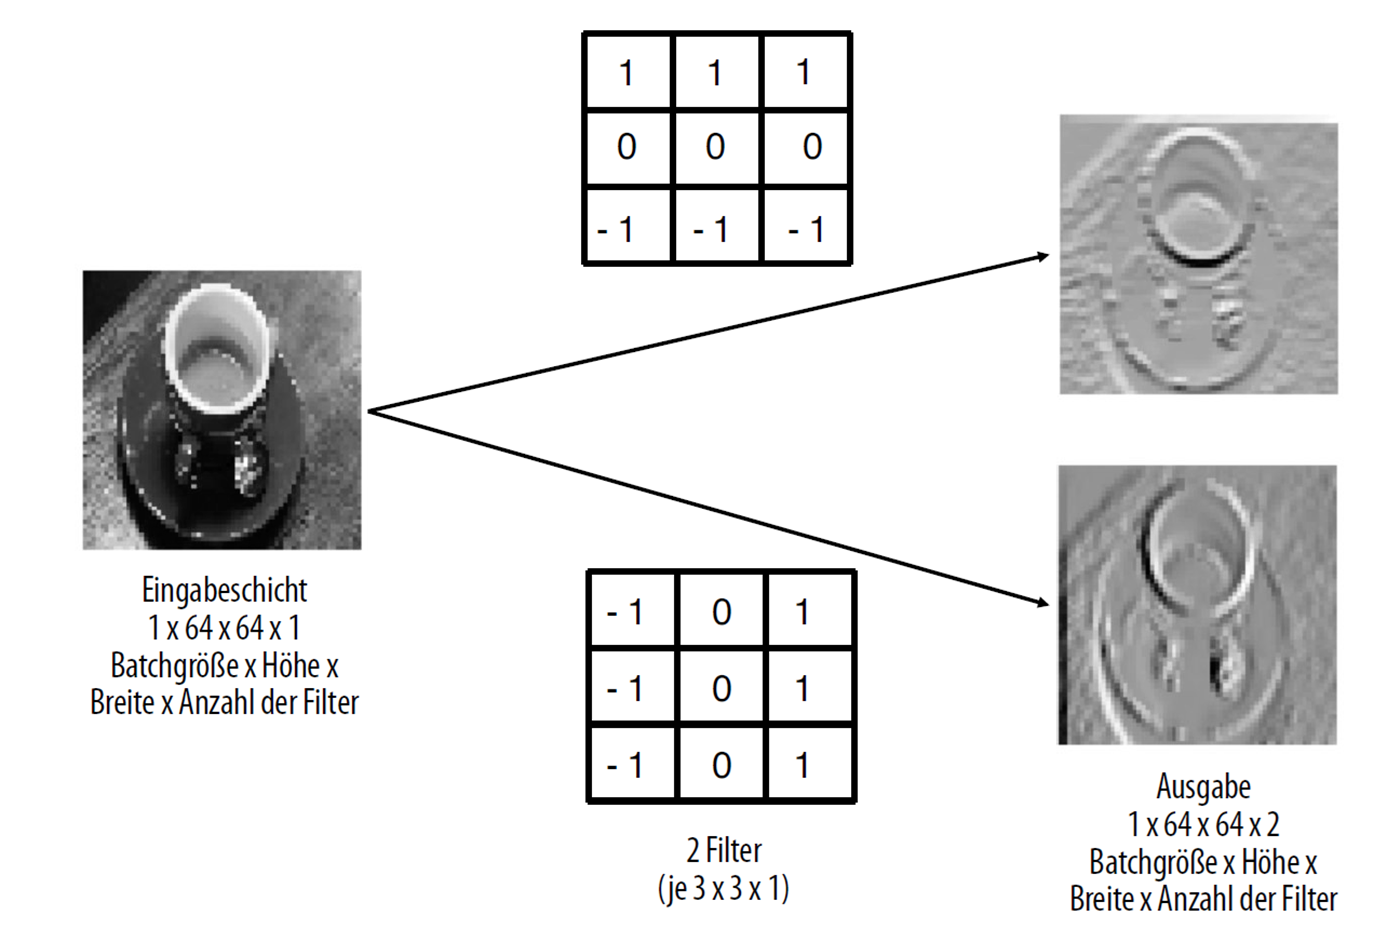

In [ ]:
class EdgeDetector(nn.Module):
    def __init__(self):
        super().__init__()
        # Kernel für horizontale und vertikale Kanten
        self.edge_hor = ### Hier horizontale Edge Detector Kernel definieren
        
        self.edge_ver = ### Hier vertikale Edge Detector Kernel definieren
        
    def forward(self, x):
        # Kernel für RGB-Bilder vorbereiten
        kernel_x = self.edge_hor.to(x.device).repeat(3, 1, 1, 1)
        kernel_y = self.edge_ver.to(x.device).repeat(3, 1, 1, 1)
        
        # Gradienten berechnen
        grad_x = torch.nn.functional.conv2d(x, kernel_x, groups=3)
        grad_y = torch.nn.functional.conv2d(x, kernel_y, groups=3)
        
        # Gradienten kombinieren
        edges = torch.sqrt(grad_x**2 + grad_y**2) # Probieren Sie aus, was passiert, wenn man eine Kante rauslässt und wie dann das Ergebnis aussieht
        return edges / edges.max()  # Normalisierung

# Anwendung
edge_detector = EdgeDetector()
edge_images = edge_detector(images)

# Ergebnisse
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
imshow(torchvision.utils.make_grid(images))
plt.title("Originalbilder")

plt.subplot(1,2,2)
imshow(torchvision.utils.make_grid(edge_images))
plt.title("Erkannte Kanten")
plt.show()